In [19]:
knn = KNeighborsClassifier(n_neighbors=7)

knn.fit(X_train, y_train)

pred = knn.predict(X_test)

print("Accuracy :", accuracy_score(y_test,pred))
print("Precision:", precision_score(y_test,pred))
print("Recall   :", recall_score(y_test,pred))
print("F1 Score :", f1_score(y_test,pred))

Accuracy : 0.895067264573991
Precision: 1.0
Recall   : 0.22
F1 Score : 0.36065573770491804


In [18]:
best_model = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(best_model)

           Model  Accuracy  Precision    Recall  F1 Score
2            SVM  0.973991   0.968992  0.833333  0.896057
3    Naive Bayes  0.968610   1.000000  0.766667  0.867925
0  Decision Tree  0.967713   0.895833  0.860000  0.877551
1            KNN  0.910314   1.000000  0.333333  0.500000


Decision Tree


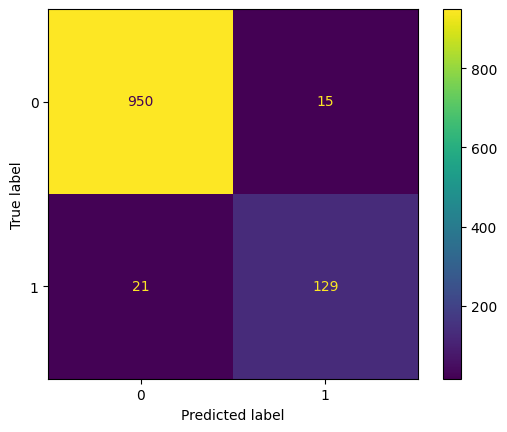

KNN


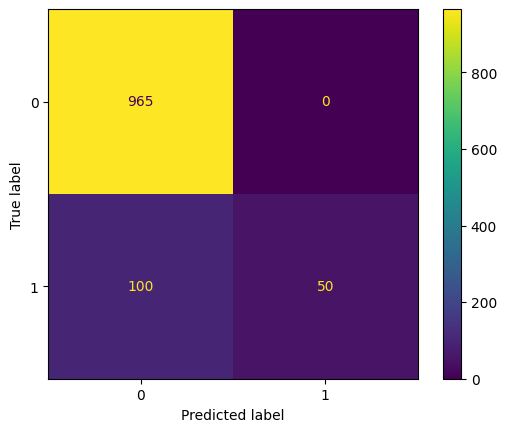

SVM


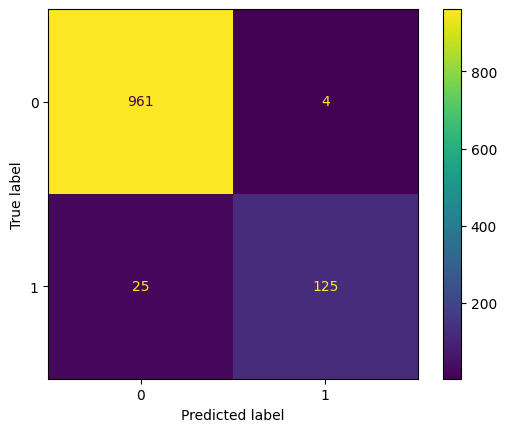

Naive Bayes


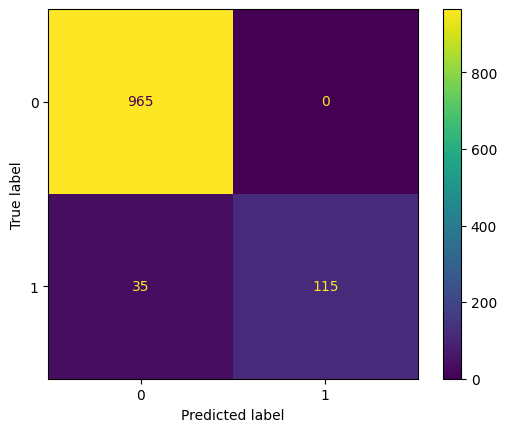

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    pred = model.predict(X_test)

    cm = confusion_matrix(y_test, pred)

    print(name)

    ConfusionMatrixDisplay(confusion_matrix=cm).plot()

    plt.show()

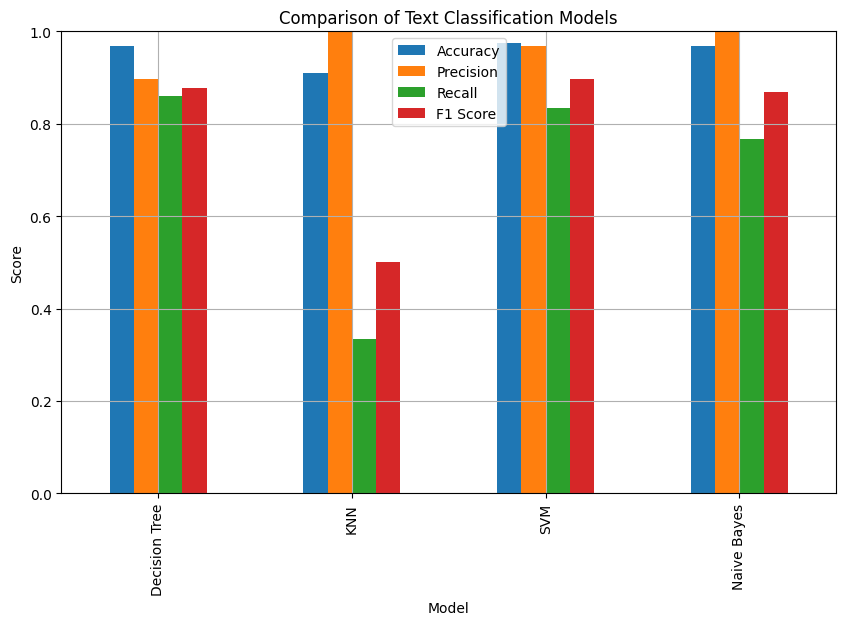

In [16]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Comparison of Text Classification Models")
plt.ylabel("Score")
plt.ylim(0,1)
plt.grid(True)

plt.show()

In [15]:
results_df = pd.DataFrame(
    results,
    columns=["Model","Accuracy","Precision","Recall","F1 Score"]
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.967713,0.895833,0.860000,0.877551
1,KNN,0.910314,1.000000,0.333333,0.500000
2,SVM,0.973991,0.968992,0.833333,0.896057
3,Naive Bayes,0.968610,1.000000,0.766667,0.867925


In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

models={
    "Decision Tree":DecisionTreeClassifier(random_state=42),
    "KNN":KNeighborsClassifier(5),
    "SVM":LinearSVC(random_state=42),
    "Naive Bayes":MultinomialNB()
}

results=[]

for name,model in models.items():

    model.fit(X_train,y_train)

    pred=model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test,pred),
        precision_score(y_test,pred),
        recall_score(y_test,pred),
        f1_score(y_test,pred)
    ])

results

[['Decision Tree',
  0.967713004484305,
  0.8958333333333334,
  0.86,
  0.8775510204081632],
 ['KNN', 0.9103139013452914, 1.0, 0.3333333333333333, 0.5],
 ['SVM',
  0.9739910313901345,
  0.9689922480620154,
  0.8333333333333334,
  0.8960573476702509],
 ['Naive Bayes',
  0.968609865470852,
  1.0,
  0.7666666666666667,
  0.8679245283018868]]

In [13]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer=TfidfVectorizer(stop_words='english')

X=vectorizer.fit_transform(df['Text'])

y=df['Label']

print(y.unique())

[0 1]


In [11]:
import pandas as pd

df = pd.read_csv("spam.csv",encoding="latin-1")

df = df[['v1','v2']]
df.columns=['Label','Text']

df['Label']=df['Label'].map({'ham':0,'spam':1})

df.head()

,Label,Text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import LinearSVC

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay